In [70]:
import math
import numpy as np
import random
from graphviz import Digraph

In [71]:
class Value:
    def __init__(self,data,child=(),label='',op=''):
        self.data=data
        self.prev=set(child)
        self.label=label
        self.op=op
        self.grad=0.0
        self._backward=lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data+other.data,(self,other),op='+')

        def backward():
            self.grad+=out.grad
            other.grad+=out.grad
            
        out._backward=backward

        return out
    
    def __radd__(self, other): # fallback when the passed args wont match the expected in add function
        return self+other
    
    def __neg__(self):
        return self*-1
    
    def __sub__(self, other):
        return self+(-other)

    def __rsub__(self, other):
        return other-self
    
    def __mul__(self, other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data*other.data,(self,other),op='*')

        def backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad     

        out._backward=backward

        return out

    def __rmul__(self, other):
        return self*other

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out=Value(self.data**other,(self,),op='pow')
    
        def backward():
            self.grad+=out.grad*(other*(self.data**(other-1)))
    
        out._backward=backward
        
        return out
    
    def __truediv__(self, other):
        return self*(other**-1)

    def exp(self):
        x=math.exp(self.data)
        out=Value(x,(self,),op='exp')

        def backward():
            self.grad+=out.grad*out.data

        out._backward=backward

        return out

    def tanh(self):
        t=math.tanh(self.data)
    
        out=Value(t,(self,),op='tanh')
    
        def backward():
            self.grad+=(1-t**2)*out.grad
    
        out._backward=backward
    
        return out
    
    def backprop(self):
        topo=[]
        visited=set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                        
                for child in v.prev:
                    build_topo(child)
            
                topo.append(v)

        build_topo(self)

        self.grad=1
        for node in reversed(topo):
            node._backward()

In [72]:
x1=Value(4.0,label='x1')
x2=Value(5.0,label='x2')

w1=Value(1.0,label='w1')
w2=Value(2.0,label='w2')

w1x1=w1*x1
w1x1.label='w1x1'

w2x2=w2*x2
w2x2.label='w2x2'

b=Value(2,label='b')

t=w1x1+w2x2
t.label='t'

s=t+b
s.label='s'

e=(2*s).exp()
e.label='e'

o=(e-1)/(e+1)
o.label='o'


In [73]:
print(f"w1.grad > {w1.grad}")
print(f"w2.grad > {w2.grad}")
print(f"x1.grad > {x1.grad}")
print(f"x2.grad > {x2.grad}")
print(f"w1x1.grad > {w1x1.grad}")
print(f"w2x2.grad > {w2x2.grad}")
print(f"t.grad > {t.grad}")
print(f"b.grad > {b.grad}")
print(f"s.grad > {s.grad}")
print(f"o.grad > {o.grad}")

o.backprop()
print("\n")

print(f"w1.grad > {w1.grad}")
print(f"w2.grad > {w2.grad}")
print(f"x1.grad > {x1.grad}")
print(f"x2.grad > {x2.grad}")
print(f"w1x1.grad > {w1x1.grad}")
print(f"w2x2.grad > {w2x2.grad}")
print(f"t.grad > {t.grad}")
print(f"b.grad > {b.grad}")
print(f"s.grad > {s.grad}")
print(f"o.grad > {o.grad}")

w1.grad > 0.0
w2.grad > 0.0
x1.grad > 0.0
x2.grad > 0.0
w1x1.grad > 0.0
w2x2.grad > 0.0
t.grad > 0.0
b.grad > 0.0
s.grad > 0.0
o.grad > 0.0


w1.grad > 2.0232049322358337e-13
w2.grad > 2.529006165294792e-13
x1.grad > 5.058012330589584e-14
x2.grad > 1.0116024661179169e-13
w1x1.grad > 5.058012330589584e-14
w2x2.grad > 5.058012330589584e-14
t.grad > 5.058012330589584e-14
b.grad > 5.058012330589584e-14
s.grad > 5.058012330589584e-14
o.grad > 1


In [74]:
class Neuron:
    def __init__(self,nin):
        self.w=[Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(random.uniform(-1,1))

    def __call__(self,x):
        s=sum(wi*xi for wi,xi in zip(self.w,x))+self.b
        out=s.tanh()
        return out

    def parameters(self):
        return self.w+[self.b]
    
class Layer:
    def __init__(self,nin,nout):
        self.neurons=[Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        out=[n(x) for n in self.neurons]
        return out

    def parameters(self):
        out=[]

        for neuron in self.neurons:
            out.extend(neuron.parameters())

        return out


class MLP:
    def __init__(self,nin,nouts):
        sz=[nin]+nouts
        self.layers=[Layer(sz[i],sz[i+1]) for i in range(len(nouts))]

    def __call__(self,x):
        for layer in self.layers:
            x=layer(x)

        return x

    def parameters(self):
        out=[]

        for layer in self.layers:
            out.extend(layer.parameters())

        return out


In [75]:
mlp=MLP(3,[3,4,4,5,3,1])
mlp_out=mlp([1,2,3])

In [76]:
x=[
    [1.0,2.0,-1.0],
    [4.0,-1.0,2.0],
    [5.0,3.5,-2.0],
    [-2.0,3.0,-1.0]
]

y_actual=[1.0,-1.0,2.0,1.0] # Output Values actual

y_pred=[mlp(i)[0] for i in x]

y_pred

[Value(data=-0.882018579568454),
 Value(data=-0.8833161315951892),
 Value(data=-0.8830477270355721),
 Value(data=-0.9075608174902581)]

In [77]:
#loss

loss=sum((pred-actual)**2 for actual,pred in zip(y_actual,y_pred))
loss # it is a Value object , because y_pred is a list of value objects.

Value(data=15.506361527775855)

In [78]:
loss.backprop()

In [79]:
for p in mlp.parameters():
    p.data+=(-0.01)*p.grad

In [80]:
x=[
    [1.0,2.0,-1.0],
    [4.0,-1.0,2.0],
    [5.0,3.5,-2.0],
    [-2.0,3.0,-1.0]
]

y_actual=[1.0,-1.0,2.0,1.0] 

for epoch in range(100):
    # forward pass
    y_pred=[mlp(i)[0] for i in x]

    # loss
    loss=sum((pred-actual)**2 for actual,pred in zip(y_actual,y_pred))

    # grad reset
    for p in mlp.parameters():
        p.grad=0.0

    # backward pass
    loss.backprop()

    # finetune
    for p in mlp.parameters():
        p.data-=0.01*p.grad

    print(epoch,loss,y_pred) 


0 Value(data=15.080571437774783) [Value(data=-0.8461387913830567), Value(data=-0.8474463010501052), Value(data=-0.8474345683982953), Value(data=-0.881804120612081)]
1 Value(data=14.41113594391599) [Value(data=-0.7881576407973008), Value(data=-0.7892798937609785), Value(data=-0.7898944213584574), Value(data=-0.8400310731272435)]
2 Value(data=13.322951533800309) [Value(data=-0.689748463278067), Value(data=-0.6902505305917533), Value(data=-0.6922626426113204), Value(data=-0.7673366385752709)]
3 Value(data=11.602336938309191) [Value(data=-0.5221905398616614), Value(data=-0.5214198093669418), Value(data=-0.5260207749532048), Value(data=-0.6356811866324359)]
4 Value(data=9.318126542820819) [Value(data=-0.2684738981308451), Value(data=-0.2663007263708341), Value(data=-0.273919465919709), Value(data=-0.4142404855501126)]
5 Value(data=7.258791869922915) [Value(data=0.014951894878025052), Value(data=0.017401004851520022), Value(data=0.008692833697242611), Value(data=-0.13492866087561672)]
6 Valu

In [81]:
y_pred=[mlp(i)[0] for i in x]

y_pred

[Value(data=0.7573743751056796),
 Value(data=0.753354901429914),
 Value(data=0.7534343074281156),
 Value(data=0.7431301966012492)]

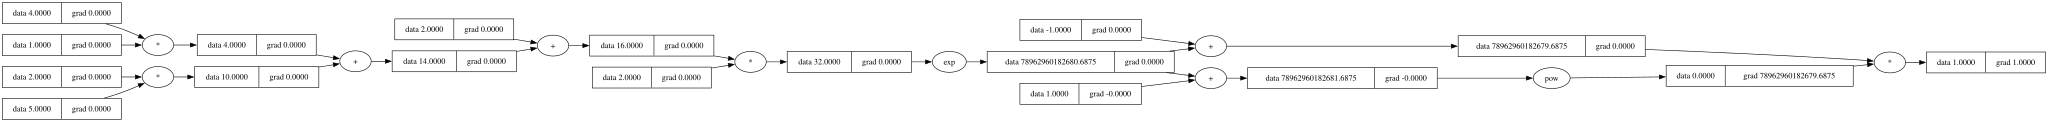

In [82]:
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v.prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{ data %.4f | grad %.4f }" % (n.data, n.grad), shape='record')
        if n.op:
            dot.node(name=str(id(n)) + n.op, label=n.op)
            dot.edge(str(id(n)) + n.op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2.op)
    
    return dot


draw_dot(o)

In [ ]:
# Example for clear picture

x=Value(2.0,label='x') # input variable
w=Value(1.0,label='w') # random initial value

y_actual=5.0

In [86]:
y=x*w

loss=(y-y_actual)**2
loss

Value(data=9.0)

In [112]:
# we need to finetune w so that y_pred moves towards y_actual

# w.grad = d(loss)/dw = 2*(x*w-y_actual)*x -> depends on w , so changing w will change w.grad
y_actual=5.0

for epoch in range(10):
    # forward pass
    y=w*x

    # loss
    loss=(y-y_actual)**2

    w.grad=0.0 # because of += in grads

    # backward pass
    loss.backprop()

    # finetuning
    w-=0.01*w.grad

    print(epoch,loss,w)

0 Value(data=7.049467140673545e-18) Value(data=2.499999998778662)
1 Value(data=5.9666674258026865e-18) Value(data=2.499999998876369)
2 Value(data=5.050186191456383e-18) Value(data=2.4999999989662594)
3 Value(data=4.274478914579016e-18) Value(data=2.4999999990489585)
4 Value(data=3.617919493904144e-18) Value(data=2.4999999991250417)
5 Value(data=3.0622083030309093e-18) Value(data=2.499999999195038)
6 Value(data=2.5918544803887306e-18) Value(data=2.499999999259435)
7 Value(data=2.1937457374416284e-18) Value(data=2.49999999931868)
8 Value(data=1.8567871667415505e-18) Value(data=2.499999999373186)
9 Value(data=1.571583945324775e-18) Value(data=2.499999999423331)
